In [1]:
from pathlib import Path
import sqlite3
import json

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import shape
from matplotlib.collections import LineCollection

PROJECT = Path(
    "/scratch/project_2010417/paper3/toronto-bike-exposure"
)

DATA = PROJECT / "data/processed"
OUTDIR = PROJECT / "outputs/maps"
OUTDIR.mkdir(parents=True, exist_ok=True)

pairs = pd.read_parquet(DATA / "full_june_od_pairs.parquet")

with sqlite3.connect(DATA / "full_june_routes.sqlite") as conn:
    routes = pd.read_sql_query(
        """
        SELECT start_id, end_id, distance_m,
               time_min, geometry_json
        FROM routes
        WHERE geometry_json IS NOT NULL
        """,
        conn
    )

routes = routes.merge(
    pairs[["Start_Station_Id", "End_Station_Id", "trip_count"]],
    left_on=["start_id", "end_id"],
    right_on=["Start_Station_Id", "End_Station_Id"],
    how="inner",
    validate="one_to_one"
)

gdf = gpd.GeoDataFrame(
    routes.drop(columns="geometry_json"),
    geometry=[shape(json.loads(x)) for x in routes["geometry_json"]],
    crs="EPSG:4326"
).to_crs("EPSG:26917")

print("Modelled routes:", f"{len(gdf):,}")
print("Trips represented:", f"{gdf['trip_count'].sum():,}")
print("Unique geometries:", f"{gdf.geometry.to_wkb().nunique():,}")

Modelled routes: 163,026
Trips represented: 737,915
Unique geometries: 163,026


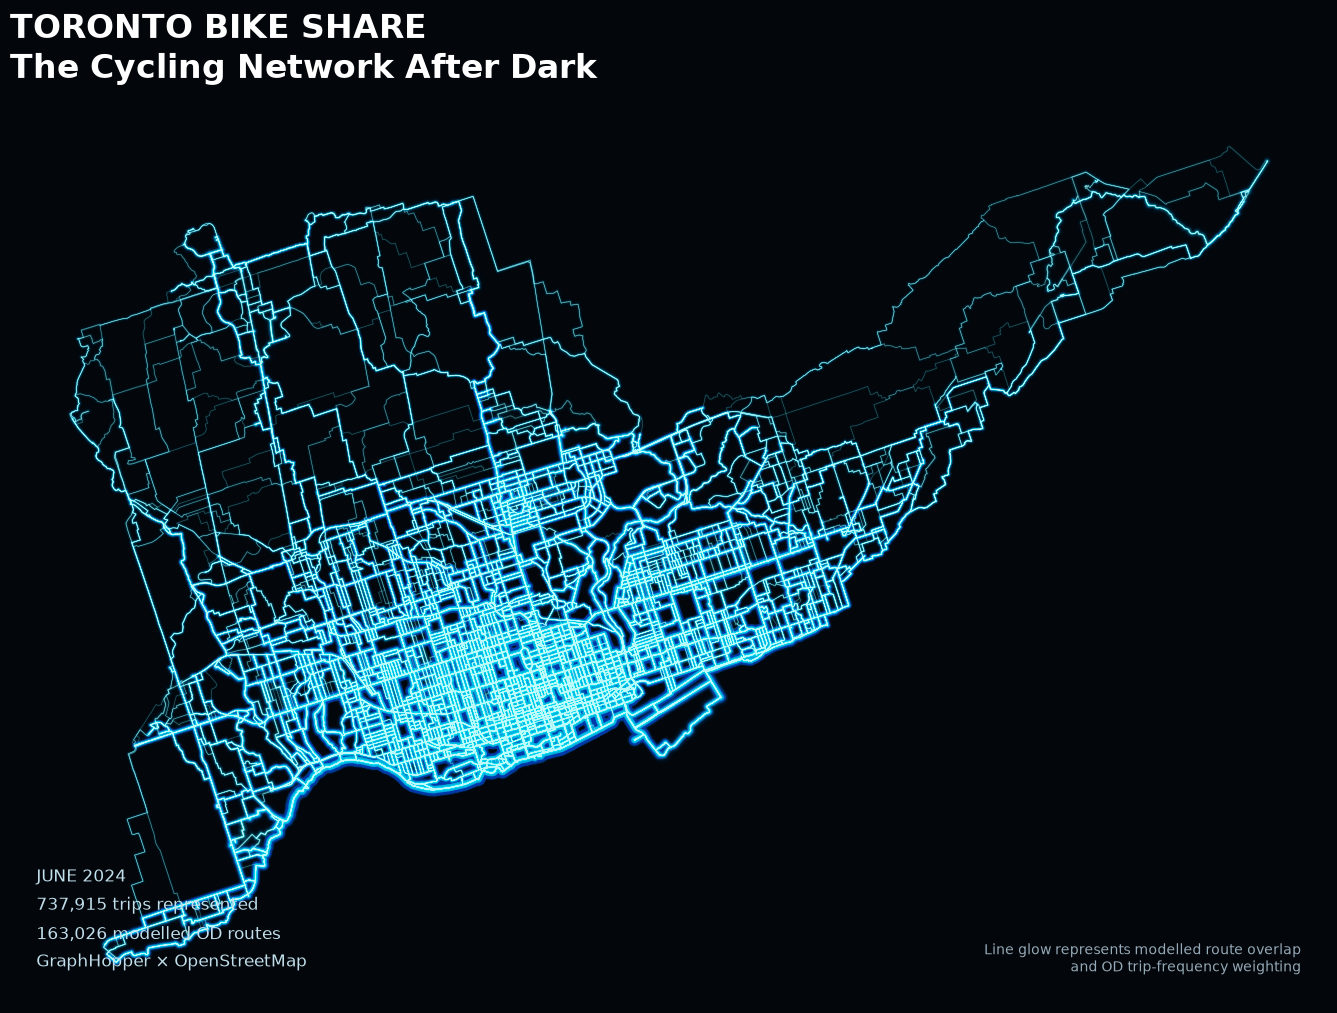

Saved: /scratch/project_2010417/paper3/toronto-bike-exposure/outputs/maps/toronto_full_june_glow.png


In [2]:
segments = []
weights = []

for geom, count in zip(gdf.geometry, gdf["trip_count"]):
    if geom.geom_type == "LineString":
        segments.append(np.asarray(geom.coords))
        weights.append(count)

weights = np.asarray(weights)

# Logarithmic scaling prevents the busiest OD pairs
# from completely dominating the image.
widths = 0.35 + 0.28 * np.log1p(weights)

fig, ax = plt.subplots(figsize=(17, 14), facecolor="#03060b")
ax.set_facecolor("#03060b")

for factor, alpha, color in [
    (7.0, 0.012, "#008cff"),
    (3.5, 0.035, "#00cfff"),
    (1.5, 0.095, "#00eeff"),
    (0.5, 0.35, "#c2ffff"),
]:
    layer = LineCollection(
        segments,
        linewidths=widths * factor,
        colors=color,
        alpha=alpha,
        capstyle="round",
        rasterized=True
    )
    ax.add_collection(layer)

ax.autoscale()
ax.set_aspect("equal")
ax.set_axis_off()

ax.set_title(
    "TORONTO BIKE SHARE\n"
    "The Cycling Network After Dark",
    loc="left",
    color="white",
    fontsize=24,
    fontweight="bold",
    pad=20
)

info = (
    f"JUNE 2024\n"
    f"{gdf['trip_count'].sum():,} trips represented\n"
    f"{len(gdf):,} modelled OD routes\n"
    "GraphHopper × OpenStreetMap"
)

ax.text(
    0.02, 0.03,
    info,
    transform=ax.transAxes,
    fontsize=12,
    color="#c0dfeb",
    va="bottom",
    linespacing=1.7
)

ax.text(
    0.98, 0.03,
    "Line glow represents modelled route overlap\n"
    "and OD trip-frequency weighting",
    transform=ax.transAxes,
    fontsize=10,
    color="#94a8b5",
    ha="right",
    va="bottom"
)

outfile = OUTDIR / "toronto_full_june_glow.png"

plt.savefig(
    outfile,
    dpi=250,
    facecolor=fig.get_facecolor(),
    bbox_inches="tight"
)

plt.show()
print("Saved:", outfile)